In [1]:
import os
from typing import TypedDict, Annotated
from langgraph.graph import StateGraph,START,END
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv
from langgraph.graph.message import add_messages
from langchain_core.messages import AIMessage, BaseMessage, HumanMessage

In [2]:
load_dotenv()

True

In [3]:
google_api_key = os.getenv("GOOGLE_API_KEY")
if not google_api_key:
    raise ValueError(
        "Set GOOGLE_API_KEY in .env to a valid Google AI Studio API key; "
        "do not use an OAuth access token."
    )

In [4]:
primary = ChatGoogleGenerativeAI(
    model="gemini-3.6-flash",
    google_api_key=google_api_key,
    max_retries=3,
)
backup = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    google_api_key=google_api_key,
    max_retries=3,
)

model = primary.with_fallbacks([backup])

In [5]:
class MessageState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

In [6]:
def chat_model(state: MessageState):
    messages = state["messages"]
    response = model.invoke(messages)
    return {"messages": [response]}

In [7]:
graph = StateGraph(MessageState)

graph.add_node("chat_model",chat_model)
graph.add_edge(START,"chat_model")

In [8]:
bot = graph.compile()

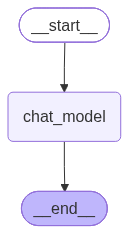

In [9]:
bot

In [10]:
response = bot.invoke({"messages": [HumanMessage(content="Hello, how are you?")]})

In [11]:
response["messages"][-1].text

"Hello! I'm doing well, thank you for asking. How are you doing today? How can I help you?"

In [12]:
response["messages"]

[HumanMessage(content='Hello, how are you?', additional_kwargs={}, response_metadata={}, id='405739cb-5807-40b6-80c6-e59cd7dc84c3'),
 AIMessage(content=[{'type': 'text', 'text': "Hello! I'm doing well, thank you for asking. How are you doing today? How can I help you?", 'extras': {'signature': 'Eq0HCqoHAWkUfRNgc84dO2CHicZW3mdfg+7/9O5fpOWrqS2K7K7gRDtSPD4xyTPHSDS4KYrHRR/TOGIpvl/nQABQMqGx1GkwFWBaj8mef2RQnw3tYvQKWc3yJN7O06bL1sO+cN3sn7CVDsT/ez0f7C4WTg4ck8WYOvRiSpnz/TyQX9NCma5RNH47C1k0R3pi/l08/xB+cPYEqPhRVeS0PB0y5H8wrnkEsM2cnCqjHdhOvQVt8WtNDLKlL7bEQtwbgUdhkNZQ6Mxf3at+Hs3XdYyccgNDMn3UsjgO8URPP4pdkexGf0Q/vhfC9Jj5GAXLwHNY9W6Gw6aJV+0yHfpv3hAWqct9W8AhagG/HIOnMAE3oIVjYUHtaj/qS73PO0H4Z207tR+x0z6VQefY9cUng1vzqL8TjyZ8FOYc0hNoVCqPr1kGN8alFZsJq+56dQvq2abzy8PAioUVxwlO18NkYcBePt4NfQeTV7EIEZ6M+gaIkwmblckidE/YZ/dwlcoNrta4fFov/+WQxAxresmwyf3JgMf3+11am1KL5GLP2hkuSi3ScuNKsZFomgX6s56PlIaev4Xc8I2uqEJVdr59J8a3pL01ETIs6h9CT1+TFEv02F7kxbnMv+xIfPZh07ksDWko3AhPSKcinUYajF+9n+kL6dK3qoXPKp17n+sGDxclmuNxz9wL7VW344Qs992b

In [13]:
type(response["messages"][1].content[0])

dict

In [14]:
type(response["messages"][1])

langchain_core.messages.ai.AIMessage

In [16]:
bot.invoke({"messages": [{"role": "user", "content": "Hi! My name is rahul."}]})

{'messages': [HumanMessage(content='Hi! My name is rahul.', additional_kwargs={}, response_metadata={}, id='45600027-3c0c-4545-ab9e-3ad035298862'),
  AIMessage(content=[{'type': 'text', 'text': "Hello Rahul! It's nice to meet you. How can I help you today?", 'extras': {'signature': 'EowECokEAWkUfRNwYI6sxroNJnwrx3mqneCERxAZ6TLuh4waX07ofViAc92qdINckzFsN+L339ouluyVrQWIo2O9haE/DR4crBk3NrhKxFgVa5kJd1cYmWjkmlWxSGMdZTntk+53QFltY3cZ1cQ49A2i3pR3SupG+/kJOMqRz1U+ykZONPFx1ayx88XUTMvog9l+dm2Bv4OG9tVu1414ENhK13cXBAxCC+reyy9fIwDfzcpgETrzQIheBg1pOo+5G0Whkyvxy3xkdvgcFHJDgQtQzmyNwTBF98IZJP3EaPe9cGpPVNQUGy+wdvqT/xlk3R+Rikj/NWKSmq/RIMMw+b+mmBcprRbi3+X8ZWEuythNODCmdxl8aqZAbmq5NxWx0fh0xVYEJeJzRHGmlRhUwxC3jlMyXGU4fvML0+GhP/ta/ZT2Y+x61/ts1tBQRi8/X7U0868PuBdwX6LMhMip/7qD+5EdDiXgqQWWBASenRTHeD5dRlvBm3SMpF7rk3uWjNtUpqrjkpUVmFfwPdIR58z7jGq1LwNQ2uBW2j93jBrh7sU04/30E/JRXezAXZI/EZ2DVVQ0/Sv7I/TSf9GYd4V8AMbEc8pK399eQTmh6SQJtslAg4rql6dxxULDlHAcu3yrUutUrK2FcVarBQX2/zHLngQ1XT2SXrfh3BitKCykXuUT/KYpL01ex3oWVZk='}}], additi

In [17]:
bot.invoke({"messages": [{"role": "user", "content": "What is my name?"}]})

{'messages': [HumanMessage(content='What is my name?', additional_kwargs={}, response_metadata={}, id='9705774f-053d-4bf0-9f53-76a5f30de6b6'),
  AIMessage(content=[{'type': 'text', 'text': "I don't know your name yet! Since this is a new conversation and I don't have access to your personal information, you'll have to tell me. \n\nWhat should I call you?", 'extras': {'signature': 'EtIFCs8FAWkUfRPsa9I1zgvVk6m0DyUY42ep+9L/sgfHtKk16ilC5/FsH9JeriL8Mlne+m8JMe+d4o2qAfp/g6Xn9kfZ3nwEfEA2ZQq4KNEE6SUcQTlfYaOmPB74gPPk7B5btAsjN+pVeDTbblICOEn9+SnOf65yd7c6tHc6o4xBSBmKV3cnHhYVj5BZSPfOqHhbAqetVSxMNEBEXBk31uFc92YAOnNROsj2h2eO/Xdc48FISv/Yz7hT16rKTIpRI1lDrpOtDIiX216VvPW7mcT95o/oKjuNgif7zyjGDL4Y7jceuGojLtwad6jIeunif2BZ+C9VpExbM5u7UVjjhb7aHoXujGlvRIRb/3i/5on7r/xldZRqPYKB9cDYSTuWCKp0lVJ6zPYX7GyX8eqW/zCiPHKj4FMdKNX0g00zQnJn2ErwqRVb3fiSQqO+M0PnCXK9cj0v6WpJT1D+dJJfMB5q5/Zem4cO7jT0pXN+I6fW5Y7rgRDleS1LkX4rRb4WmlV03yBPETSDEuw3VmOdFzoC/aUUo5QtWok5LsEl+TGN4tCC3yJxTcPOTWmjVxxNZ+xn7an4w0OW0+lWFQesk7lt4D88myVWAORuvCS9